In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns 

In [2]:
synthetic_train = pd.read_csv('anthrax_decision_support_data.csv')
synthetic_train.head()

,Fever,Convulsions,Resp_Cardiac_Distress,Rumination Cessation,Milk Production Loss,Abortion,Bloody_Discharge,Edema,Reduced_Appetite,Lethargy,Staggering,Somnolence,Recumbence,Trembling,Anthrax
0,0,0,0,1,1,1,1,0,0,1,0,1,0,1,0
1,1,0,0,1,1,0,0,1,0,1,0,1,0,1,1
2,1,0,1,1,1,0,0,0,1,0,1,0,0,0,1
3,1,0,1,1,1,0,1,1,0,1,0,0,0,1,1
4,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0


In [3]:
synthetic_train = synthetic_train.drop_duplicates()

In [4]:
field_test = pd.read_csv("Anthrax field data updated.csv")
field_test.head(3)

,Fever,Convulsions,Resp_Cardiac_Distress,Rumination Cessation,Milk Production Loss,Abortion,Bloody_Discharge,Edema,Reduced_Appetite,Lethargy,Staggering,Somnolence,Recumbence,Trembling,Anthrax
0,1,1,0,1,1,0,0,0,1,0,1,0,1,1,1
1,1,1,1,1,0,0,0,0,1,0,1,0,0,1,1
2,1,1,0,1,1,1,1,1,0,0,1,0,1,1,1


In [5]:
synthetic_train[synthetic_train.columns] = synthetic_train[synthetic_train.columns].astype('float64')

In [6]:
field_test[field_test.columns] = field_test[field_test.columns].astype('float64')

In [7]:
x = synthetic_train.iloc[: , [0,1,2,3,4,5,6,7,8,9,10,11,12,13]]
y = synthetic_train.iloc[: , -1]

In [8]:
x_test = field_test.iloc[: , [0,1,2,3,4,5,6,7,8,9,10,11,12,13]]
y_test = field_test.iloc[: , -1]

In [9]:
from sklearn.model_selection import train_test_split

x_train, x_dev, y_train, y_dev = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)

In [ ]:
Fitting 5 folds for each of 50 candidates, totalling 250 fits
Best Parameters Found: {'classifier__colsample_bytree': np.float64(0.8099025726528951), 'classifier__gamma': np.float64(0.21597250932105788), 'classifier__learning_rate': np.float64(0.09445645065743215), 'classifier__max_depth': 5, 'classifier__min_child_weight': 10, 'classifier__n_estimators': 287, 'classifier__subsample': np.float64(0.7465447373174767)}
Best Cross-Validation Roc-AUC: 0.9735192577030812

In [12]:
from xgboost import XGBClassifier

xgb = XGBClassifier(
    colsample_bytree = 0.81,
    gamma = 0.21,
    learning_rate = 0.094,
    max_depth = 5,
    min_child_weight = 10,
    n_estimators = 287, 
    subsample = 0.74,
    random_state=42,
    eval_metric='logloss'
    
)

In [13]:
xgb.fit(x_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.81, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=0.21,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.094, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=5, max_leaves=None,
              min_child_weight=10, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=287, n_jobs=None,
              num_parallel_tree=None, ...)

In [14]:
y_prob = xgb.predict_proba(x_test)[:, 1]

In [15]:
from sklearn.metrics import classification_report, confusion_matrix

y_pred = (y_prob >= 0.5).astype(int)

print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

              precision    recall  f1-score   support

         0.0       1.00      0.61      0.76        31
         1.0       0.60      1.00      0.75        18

    accuracy                           0.76        49
   macro avg       0.80      0.81      0.76        49
weighted avg       0.85      0.76      0.76        49

[[19 12]
 [ 0 18]]


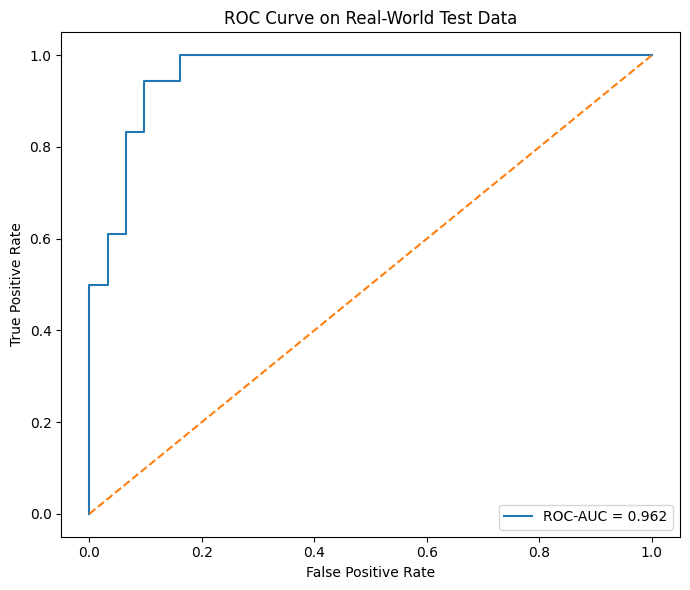

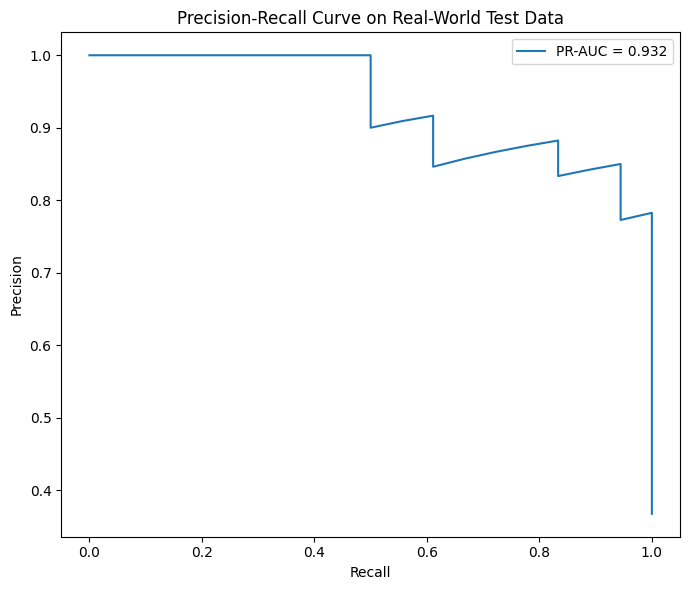

ROC-AUC: 0.962
PR-AUC:  0.932


In [16]:
from sklearn.metrics import (
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score
)

# Predicted probabilities on real-world test data
y_prob_real = xgb.predict_proba(x_test)[:, 1]

# =========================
# ROC-AUC
# =========================
fpr, tpr, _ = roc_curve(y_test, y_prob_real)
roc_auc = roc_auc_score(y_test, y_prob_real)

plt.figure(figsize=(7, 6))
plt.plot(fpr, tpr, label=f"ROC-AUC = {roc_auc:.3f}")
plt.plot([0, 1], [0, 1], "--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve on Real-World Test Data")
plt.legend()
plt.tight_layout()
plt.show()


# =========================
# PR-AUC
# =========================
precision, recall, _ = precision_recall_curve(y_test, y_prob_real)
pr_auc = average_precision_score(y_test, y_prob_real)

plt.figure(figsize=(7, 6))
plt.plot(recall, precision, label=f"PR-AUC = {pr_auc:.3f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve on Real-World Test Data")
plt.legend()
plt.tight_layout()
plt.show()

print(f"ROC-AUC: {roc_auc:.3f}")
print(f"PR-AUC:  {pr_auc:.3f}")

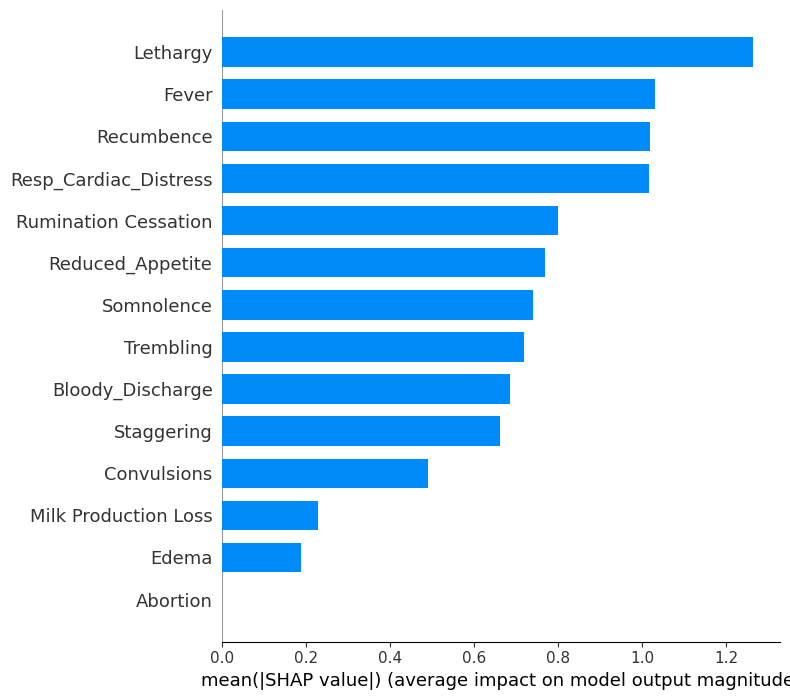

In [21]:
import shap

explainer = shap.Explainer(xgb, x_train)

# SHAP values
shap_values = explainer(x_test)

# Global summary plot
shap.summary_plot(
    shap_values,
    x_test,
    plot_type="bar"
)

In [10]:
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier

pipeline = Pipeline([
    ('classifier', XGBClassifier(
        random_state=42,
        eval_metric='logloss'
    ))
])

In [11]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from scipy.stats import randint, uniform

param_dist = {
    'classifier__n_estimators': randint(100, 401),
    'classifier__max_depth': randint(3, 11),
    'classifier__learning_rate': uniform(0.01, 0.29),
    'classifier__subsample': uniform(0.6, 0.4),
    'classifier__colsample_bytree': uniform(0.6, 0.4),
    'classifier__min_child_weight': randint(1, 11),
    'classifier__gamma': uniform(0, 0.5)
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

random_search = RandomizedSearchCV(
    estimator=pipeline,
    param_distributions=param_dist,
    n_iter=50,
    cv=cv,
    scoring='roc_auc',
    n_jobs=-1,
    verbose=2,
    random_state=42,
    return_train_score=True
)

random_search.fit(x, y)

print("Best Parameters Found:", random_search.best_params_)
print("Best Cross-Validation Roc-AUC:", random_search.best_score_)

Fitting 5 folds for each of 50 candidates, totalling 250 fits
Best Parameters Found: {'classifier__colsample_bytree': np.float64(0.8099025726528951), 'classifier__gamma': np.float64(0.21597250932105788), 'classifier__learning_rate': np.float64(0.09445645065743215), 'classifier__max_depth': 5, 'classifier__min_child_weight': 10, 'classifier__n_estimators': 287, 'classifier__subsample': np.float64(0.7465447373174767)}
Best Cross-Validation Roc-AUC: 0.9735192577030812
